# 09 · Bring your Global Fishing Watch export

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=09_gfw_workbench.ipynb)

**Evidence: a synthetic schema example by default; your own real export only when you supply it.** This workbench shows how to inspect and map apparent fishing hours without placing an API token in a public notebook.

Sources: [GFW download guidance](https://globalfishingwatch.org/faqs/how-can-i-obtain-global-fishing-watch-data-or-code/), [4Wings report fields](https://api-doc.globalfishingwatch.org/our-apis/documentation/docs/v3/4wings/report), [current terms](https://globalfishingwatch.org/terms-of-use/). Current GFW platform terms are distinct from the CC BY 4.0 publication data used elsewhere in this book.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## Obtain a bounded export
Open the GFW map, choose a small region and time interval, and download a spatially resolved apparent-fishing-activity CSV. Extract downloaded archives first, keeping the caveat and citation files. Alternatively use a versioned static download. Upload the CSV through the lab file browser. API report and static-file column names differ; inspect your file and select the explicit mapping below. Do not put an API token into notebook cells, outputs, query strings or Git commits.

In [2]:
USE_DEMO=True
YOUR_CSV="data/private/my_gfw_export.csv"
# Canonical mapping for a 4Wings spatial report; edit for the actual file.
COLUMNS={"lat":"lat","lon":"lon","hours":"hours"}
# Static portal files may use cell_ll_lat, cell_ll_lon and fishing_hours.
# For those, use a mapping and explicitly set CELL_SIZE_DEGREES from its metadata.
CELL_SIZE_DEGREES=None  # None means incoming coordinates are already cell centers.
if USE_DEMO:
    raw=pd.DataFrame({"lat":[54.1,54.2,54.3,54.2],"lon":[12.0,12.1,12.2,12.3],"hours":[1.5,3.0,2.0,4.5]})
    label="SYNTHETIC SCHEMA EXAMPLE — not a GFW observation"
else:
    raw=pd.read_csv(YOUR_CSV)
    label="USER-SUPPLIED EXPORT — record source, dataset version, period and license below"
print(label)
display(raw.head())

SYNTHETIC SCHEMA EXAMPLE — not a GFW observation


,lat,lon,hours
0,54.1,12.0,1.5
1,54.2,12.1,3.0
2,54.3,12.2,2.0
3,54.2,12.3,4.5


## Validate before plotting
Reject missing, nonnumeric, negative or out-of-range values. Missing effort is not silently replaced by zero. If a file supplies lower-left cell coordinates, add half its **documented** cell size, rather than guessing a resolution. Grouped totals without spatial coordinates cannot be mapped with this adapter.

,lat,lon,hours
0,54.1,12.0,1.5
1,54.2,12.1,3.0
2,54.3,12.2,2.0
3,54.2,12.3,4.5


Total apparent fishing hours in this table: 11.0


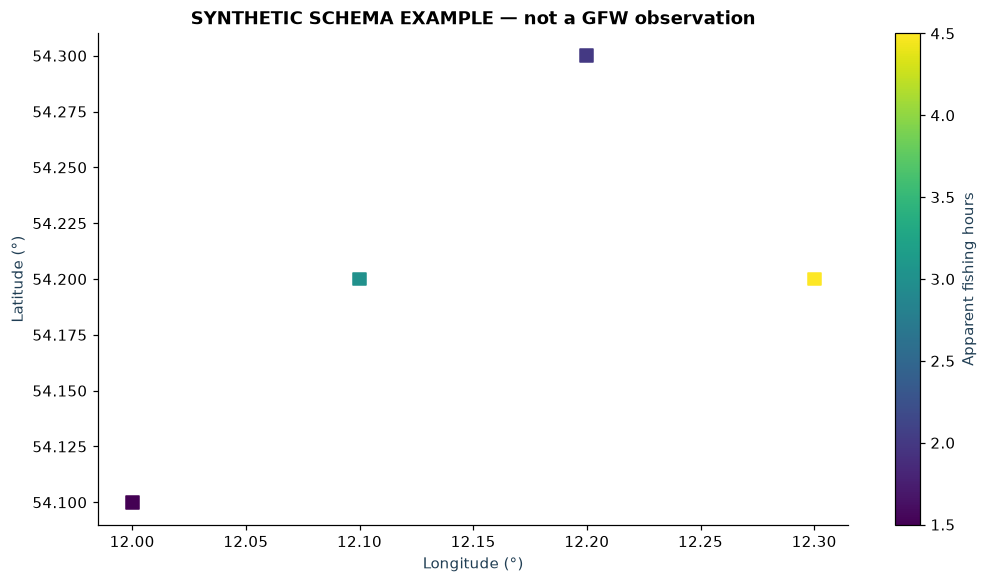

In [3]:
def normalize_effort(frame,mapping,cell_size=None):
    required=[mapping[k] for k in ["lat","lon","hours"]]
    if not set(required).issubset(frame.columns):
        raise ValueError(f"Expected columns {required}; found {list(frame.columns)}")
    out=frame[required].copy();out.columns=["lat","lon","hours"]
    for column in out:out[column]=pd.to_numeric(out[column],errors="raise")
    if not np.isfinite(out.to_numpy()).all():raise ValueError("Missing or nonfinite values require explicit investigation")
    if cell_size is not None:
        if not 0<cell_size<=10:raise ValueError("Supply a documented positive grid size in degrees")
        out[["lat","lon"]]+=cell_size/2
    if not out.lat.between(-90,90).all() or not out.lon.between(-180,180).all():raise ValueError("Coordinates outside WGS84 ranges")
    if (out.hours<0).any():raise ValueError("Negative apparent fishing hours")
    return out
effort=normalize_effort(raw,COLUMNS,CELL_SIZE_DEGREES)
display(effort)
print("Total apparent fishing hours in this table:",effort.hours.sum())
fig,ax=plt.subplots()
p=ax.scatter(effort.lon,effort.lat,c=effort.hours,s=70,cmap="viridis",marker="s")
ax.set(xlabel="Longitude (°)",ylabel="Latitude (°)",title=label)
fig.colorbar(p,ax=ax,label="Apparent fishing hours");plt.show()

## Keep a source record with the result
When using real data, replace the placeholders below before sharing. Dataset aliases such as `latest` can move; record the resolved version and retrieval date. Do not redistribute a provider export without checking its license and any restrictions in its accompanying caveat file.

In [4]:
source_record={"mode":"synthetic" if USE_DEMO else "user-supplied",
    "provider":"teaching example" if USE_DEMO else "Global Fishing Watch",
    "dataset_version":"not applicable" if USE_DEMO else "REQUIRED: resolved dataset version",
    "period":"invented" if USE_DEMO else "REQUIRED: observation interval",
    "retrieval_date":"not applicable" if USE_DEMO else "REQUIRED: YYYY-MM-DD",
    "license":"original teaching example" if USE_DEMO else "REQUIRED: export-specific license",
    "coordinate_semantics":"cell centers" if CELL_SIZE_DEGREES is None else f"SW corner + {CELL_SIZE_DEGREES/2}°"}
display(pd.Series(source_record))

mode                                    synthetic
provider                         teaching example
dataset_version                    not applicable
period                                   invented
retrieval_date                     not applicable
license                 original teaching example
coordinate_semantics                 cell centers
dtype: object

**Next question:** compare your effort layer with the SAR study only after aligning periods, spatial support and units. The bundled SAR record ends in 2021 and measures normalized presence. An effort export measures modeled hours. Their numerical values cannot be subtracted to estimate hidden fishing hours.

For larger authenticated workflows, use the [official GFW Python client](https://github.com/GlobalFishingWatch/gfw-api-python-client) in a local or managed environment with secret handling outside notebook outputs.